In [1]:
# imports 
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

## Stability Regions 

Following the derivation in these [lecture notes](https://jonshiach.github.io/ODEs-book/_pages/4.1_ERK_stability_function.html) from Manchester Metropolian University, the general equation for stability of RK methods is: $$R(z) = 1 + z\textbf{b}^T(I-z\textbf{A})^{-1}\textbf{e}$$ where $z=h\lambda$, $e=[1, 1, ..., 1]$, and $(A,b)$ come from the RK method butcher block. Using the butcher blocks for the two methods examined, RK45 & RADAU5, we're able to plot regions of absolute stability in the complex plane.

In [5]:
# ------------------------------------------------------------
# Dormand-Prince 5(4) (the method behind RK45), 7 stages (FSAL)
# ------------------------------------------------------------
c_dp = np.array([0, 1/5, 3/10, 4/5, 8/9, 1, 1])

A_dp = np.array([
    [0,            0,           0,           0,          0,            0,        0],
    [1/5,          0,           0,           0,          0,            0,        0],
    [3/40,         9/40,        0,           0,          0,            0,        0],
    [44/45,       -56/15,       32/9,        0,          0,            0,        0],
    [19372/6561,  -25360/2187,  64448/6561, -212/729,    0,            0,        0],
    [9017/3168,   -355/33,      46732/5247,  49/176,    -5103/18656,   0,        0],
    [35/384,       0,           500/1113,    125/192,   -2187/6784,    11/84,     0],
])

# 5th-order weights: propagated solution (equal to the last row of A, FSAL, so b[6] = 0)
b5_dp = np.array([35/384, 0, 500/1113, 125/192, -2187/6784, 11/84, 0])

# 4th-order weights: embedded solution, used only for error estimation
b4_dp = np.array([5179/57600, 0, 7571/16695, 393/640, -92097/339200, 187/2100, 1/40])

# ------------------------------------------------------------
# Radau IIA, 3 stages, order 5 (RADAU5)
# ------------------------------------------------------------
s6 = np.sqrt(6.0)

c_rad = np.array([(4 - s6)/10, (4 + s6)/10, 1.0])

A_rad = np.array([
    [(88 - 7*s6)/360,     (296 - 169*s6)/1800,  (-2 + 3*s6)/225],
    [(296 + 169*s6)/1800, (88 + 7*s6)/360,      (-2 - 3*s6)/225],
    [(16 - s6)/36,        (16 + s6)/36,          1/9],
])

b_rad = A_rad[-1].copy()   # stiffly accurate: b = last row of A

In [6]:
# ------------------------------------------------------------
# Stability eqn for RK methods
# ------------------------------------------------------------
def stability_R(A, b):
    """R(z) as a callable, via R = 1 + z b^T (I - zA)^{-1} 1 (works for explicit and implicit)."""
    s = len(b); one = np.ones(s); I = np.eye(s)
    def R(z):
        z = np.asarray(z, dtype=complex)
        out = np.empty(z.shape, dtype=complex)
        for idx, zi in np.ndenumerate(z):
            out[idx] = 1 + zi * (b @ np.linalg.solve(I - zi*A, one))
        return out
    return R

In [10]:
# ------------------------------------------------------------
# Stability eqn for RADAU5, RK4 and RK5
# ------------------------------------------------------------
R_dp5 = stability_R(A_dp, b5_dp)
R_dp4 = stability_R(A_dp, b4_dp)   # embedded method's stability function (not used for marching)
R_rad = stability_R(A_rad, b_rad)

In [30]:
def plot_stability_region(R, xlim=(-5, 2), ylim=(-4, 4), n=600, Title="title" ):
    x = np.linspace(*xlim, n)
    y = np.linspace(*ylim, n)
    X, Y = np.meshgrid(x, y)
    mag = np.abs(R(X + 1j * Y))

    plt.contourf(X, Y, mag, levels=[0, 1], colors="C0", alpha=0.35)
    plt.contour(X, Y, mag, levels=[1], colors="C0", linewidths=2)


    plt.xlabel("Re(z),  z = hλ")
    plt.ylabel("Im(z)")
    plt.title(f"Stability region |R(z)| ≤ 1 for {Title}") 
    plt.axhline(0, color="k", lw=0.6) 
    plt.axvline(0, color="k", lw=0.6)
    plt.grid(alpha=0.3)
    plt.show()
    

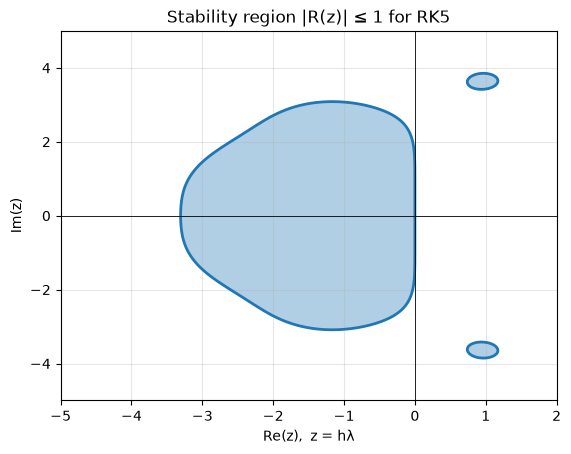

In [31]:
plot_stability_region(R_dp5, (-5, 2), (-5, 5), Title="RK5")


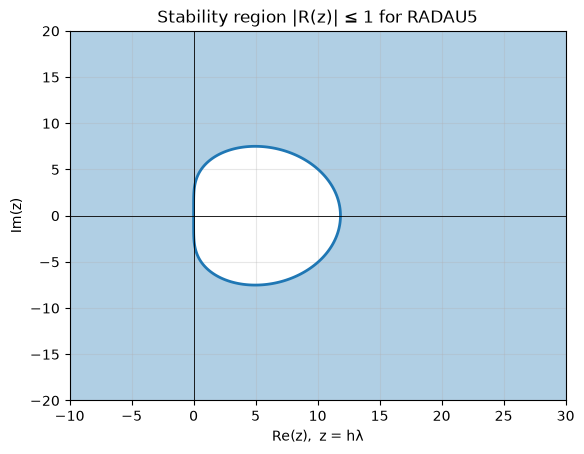

In [32]:
plot_stability_region(R_rad, (-10, 30), (-20, 20), Title="RADAU5")

## Stability of Our ODE 

Analyzing only the behvaior of CSTR 1, we have our ODE equations given as

$$\frac{dC_{A1}}{dt} = \frac{F}{V_1}\left(C_{A0} - C_{A1}\right) - k_1 C_{A1} + k_3 C_{B1} C_{C1}$$

$$\frac{dC_{B1}}{dt} = -\frac{F}{V_1} C_{B1} + k_1 C_{A1} - k_2 C_{B1}^2 - k_3 C_{B1} C_{C1}$$

$$\frac{dC_{C1}}{dt} = -\frac{F}{V_1} C_{C1} + k_2 C_{B1}^2$$

We can write this as a matrix in the form of a state vector 

 $$ y = \begin{bmatrix}
    C_A \\
    C_B \\
    C_C 
\end{bmatrix} $$

and equations 

$$ f(y) = \begin{bmatrix}
    \frac{F}{V_1}\left(C_{A0} - C_{A1}\right) - k_1 C_{A1} + k_3 C_{B1} C_{C1} \\
    \frac{F}{V_1} C_{B1} + k_1 C_{A1} - k_2 C_{B1}^2 - k_3 C_{B1} C_{C1} \\
    \frac{F}{V_1} C_{C1} + k_2 C_{B1}^2
\end{bmatrix}$$

Then the jacobian looks like 

$$ J(f(y)) = \begin{bmatrix}
    \frac{F}{V}-k_1 & k_3C_{C1} & k_3C_B \\
    k_1 & -\frac{F}{V} - 2k_2C_B-k_3C_C & -k_3C_B \\ 
    0 & 2k_2C_B & -\frac{F}{V}
\end{bmatrix} 
$$

plugging in our constants $\frac{F}{V} = 0.1, k_1 = 0.04, k_2 = 3e7, k_3 = 1e4$ gives a jacobian as a function of our state that looks like 

$$\begin{bmatrix}
    -0.14 & 1*10^4C_C & 10^4C_B \\
    0.04 & -0.1-6*10^7C_B-10^4C_C & -10^4C_B \\
    0 & 6*10^7C_B & -0.1 
\end{bmatrix}$$

For our CSTR 1, with a tiny perturbation from the initial conditions of both reactors containing the feed composition, with $y_0 = \begin{bmatrix} 1.0 \\ 0.0 \\ 0.0 \end{bmatrix}$

In [35]:
def jacobian_cstr1(y, F, V, k1, k2, k3):
    CA, CB, CC = y

    d = F/V

    return np.array([
        [-d-k1,          k3*CC,                k3*CB],
        [k1,            -d-2*k2*CB-k3*CC,    -k3*CB],
        [0.0,            2*k2*CB,            -d]
    ])

In [49]:
# constants 
F = 1.0          # volumetric flow rate
V1 = 10.0        # reactor 1 volume
V2 = 10.0        # reactor 2 volume
CA0 = 1.0        # A concentration in the CSTR 1 feed
k1 = 0.04       # 1/s
k2 = 3e7         # rate constant for B + B -> C + B
k3 = 1e4         # rate constant for B + C -> A + C

# initial state in reactor 1, slightly perturbed
y = np.array([0.999, 0.001, 0.001]) 

J = jacobian_cstr1(y, F, V1, k1, k2, k3)

eigvals = np.linalg.eigvals(J)
eigvals

array([-6.00001e+04+0.j, -1.00000e-01+0.j, -1.01400e+01+0.j])

We need a step size h so that even the largest eigenvalue product is still in the region of stability, for RK45 it looks like $ |h\lambda| \le ~3.31$, and we have the real portion of our largest eigenvalue (since there's no oscilitory behavior) as $-6*10^4$, so our step size for RK45 limited by stability is $ h \le \frac{3.31}{6*10^4} \rightarrow h \le 5.5*10^{-5}$. 

The largest step size (at this state $ \textbf{Y} = \begin{bmatrix} 0.999 \\ 0.001 \\ 0.001 \end{bmatrix}$), limited by the stability of the system, largely constrained by the wide range in reaction rates $k_1, k_2, k_3$, is given by a step size $h = 5.5\times10^{-5}$

Comparitively, the step size of RADAU5 is not limited by stability as the stability plot shows that the entire LHP region is stable. This means that any selection of step size will still result in a stable system, and that step size is limited by accuracy instead of stability.

## Accuracy determination of step size

Since RK45 is a 5th order method, the error term is $O(\lambda h^6)$, and setting that equal to the allowed error tolerance for your algorithm, you get an accuracy limited step size as $(\lambda h)^6 = tol \rightarrow h = \frac{tol^{1/6}}{|\lambda|}$ 

In [50]:
lam_fast = np.max(np.abs(np.real(eigvals)))
lam_slow = np.min(np.abs(np.real(eigvals)))
tol = 10**-6

h_stability = 3.31 / lam_fast # upper bound of stability region for RK45 lies at around Re(z) = 3.31
h_accuracy = tol**(1/6) / lam_slow # tolerance^(1/6) due to error term for 5th order methods

print(f"The step size determined by accuracy for both methods is {h_accuracy:.5f}")
print(f"The step size determined by stability for RK45 is {h_stability:.6f}")


The step size determined by accuracy for both methods is 1.00000
The step size determined by stability for RK45 is 0.000055


We can see that the difference between the two is 5 orders of magnitude, and so since the step size for RK45 is limited by stability and the step size for RADAU5 is only limited by accuracy. This is also only the step size slightly off our initial conditions, and the difference between the step sizes increases as the concentration of A decreases. 